In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [2]:
sb.set_palette('colorblind')

In [3]:
cell_types = [
   'HSC_MPP','HAEMATOPOIETIC','ENDOTHELIUM','OTHER'
]

palette_dict = dict(zip(cell_types, sb.color_palette("colorblind")))

In [4]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [15]:
# figure directory
fig_path = '/nfs/team205/cs42/HSC/HSC_new_to_transfer/figure/'
sc.settings.figdir = fig_path

# Load data

In [18]:
adata = sc.read('write/SPI1_CONSTITUTIVE_selected_celltypist.h5ad')

# Plot TF overexpression 

In [19]:
Counter(adata.obs['TF_calling'])

Counter({nan: 8971,
         'EXOG_NFE2': 1192,
         'EXOG_GFI1B': 1188,
         'EXOG_HLF': 979,
         'EXOG_GFI1': 347,
         'EXOG_SPI1': 229,
         'EXOG_EGFP': 2})

In [20]:
exog_list = adata.obs['TF_calling'].cat.categories

tf_list = [tf.split('_')[1] for tf in exog_list]
# remove gene not in adata.var_names -- EGFP
tf_list = [gene for gene in tf_list if gene in adata.var_names]

In [21]:
# remove EGFP from exog_list as only 2 cells 
exog_list = [x for x in exog_list if x != 'EXOG_EGFP']
adata = adata[adata.obs['TF_calling'].isin(exog_list)]

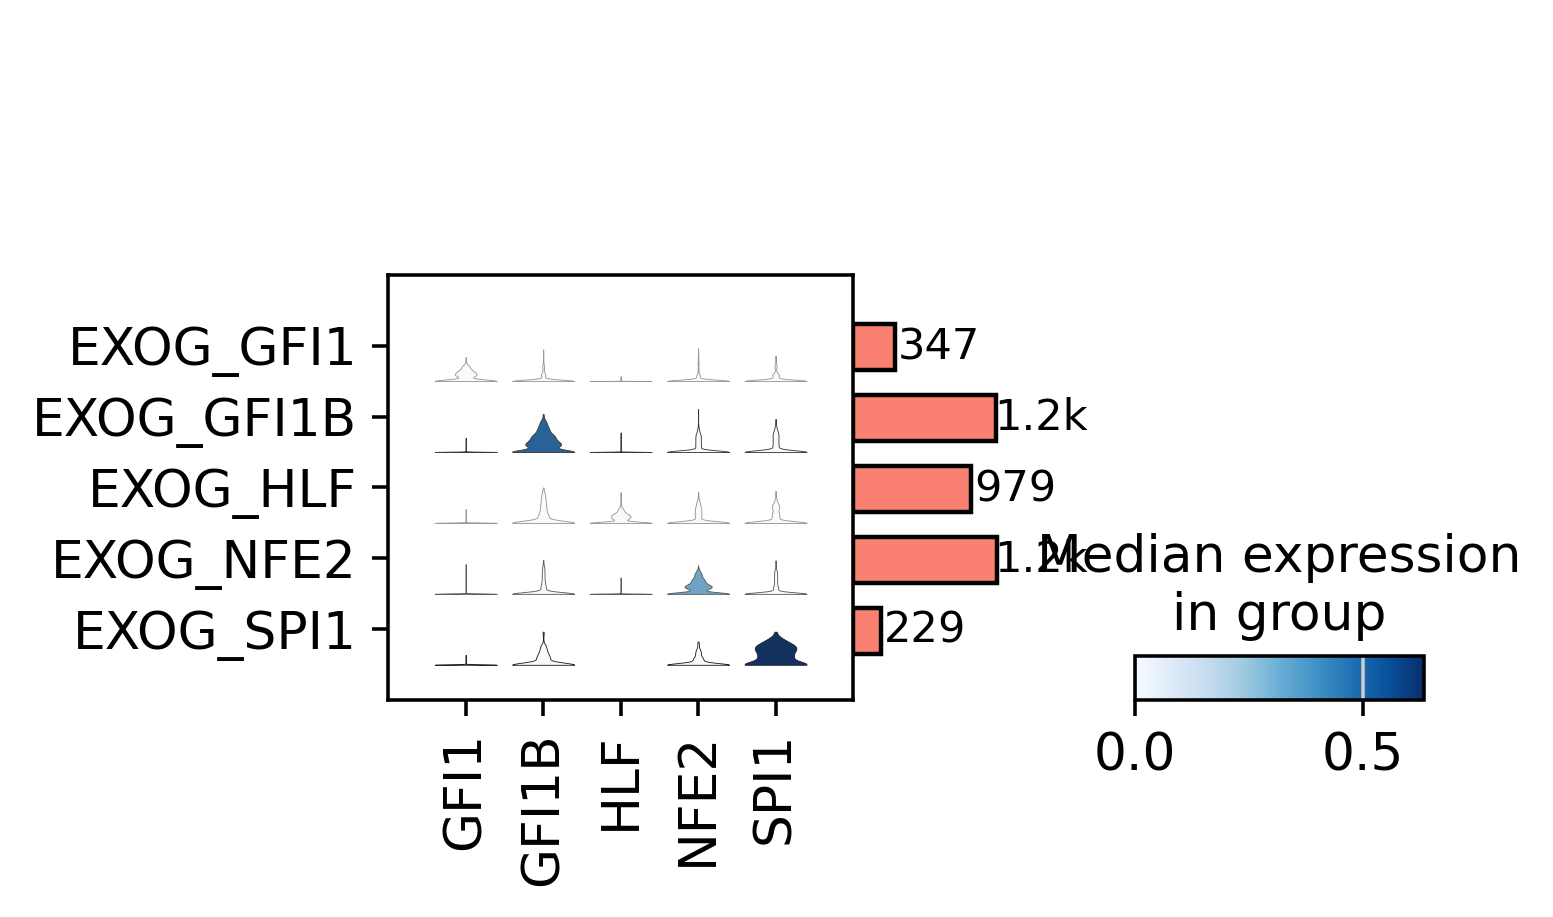

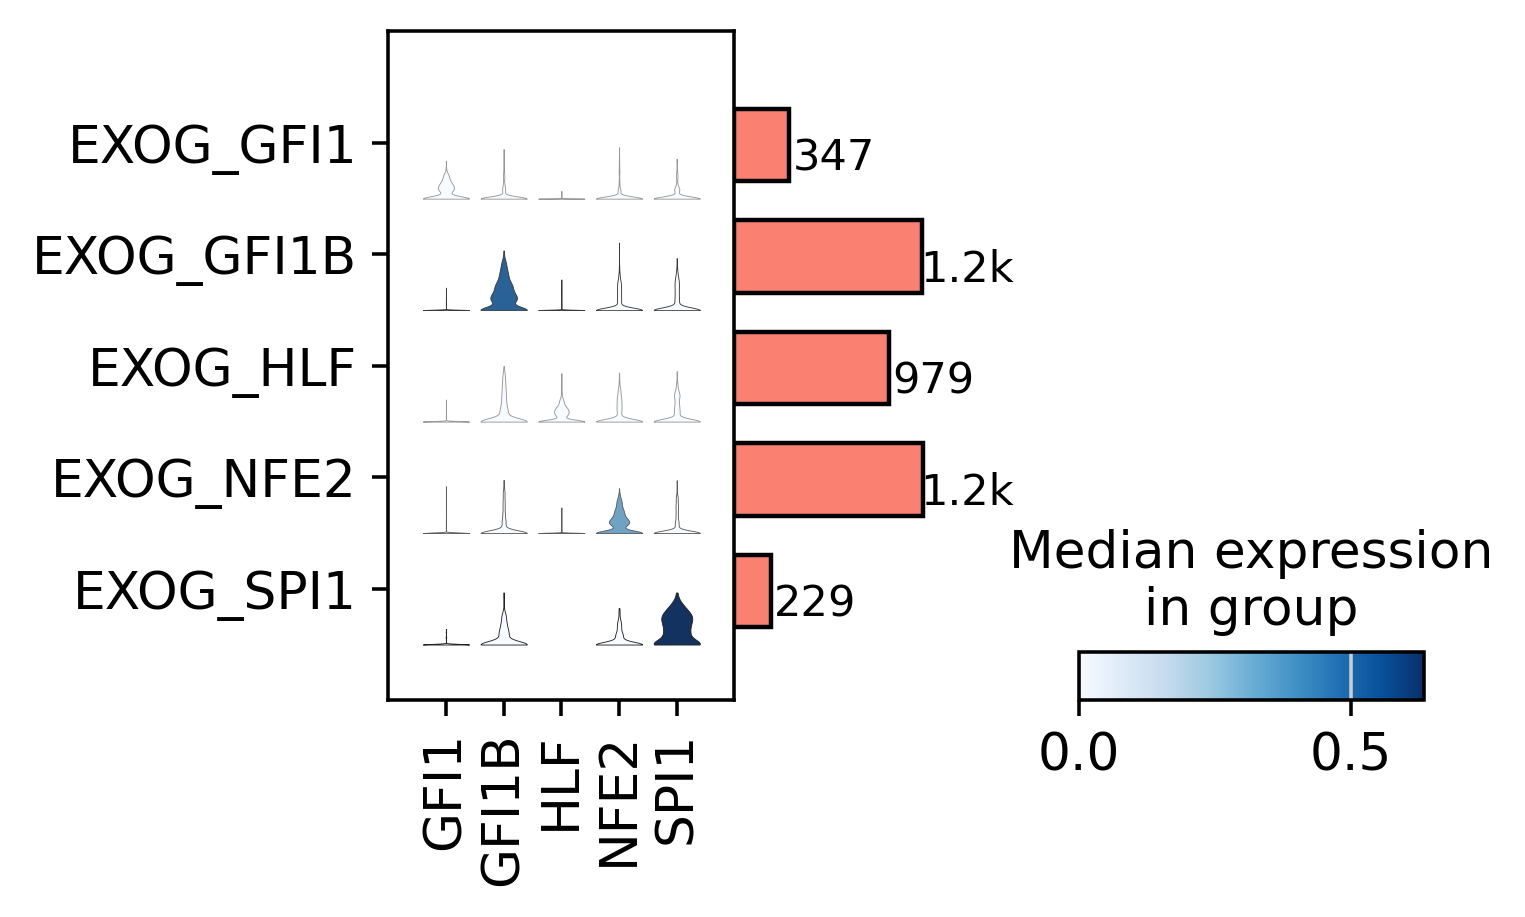

In [22]:
#sc.pl.stacked_violin(adata, var_names = tf_list, groupby = 'TF_calling', save = 'CONSTITUTIVE_SPI1_tf_overexpression.pdf')

vp = sc.pl.stacked_violin(adata, tf_list, 'TF_calling', return_fig=True)
vp.add_totals().style(ylim=(0,5)).show()
vp.savefig(fig_path+"CONSTITUTIVE_SPI1_tf_overexpression.pdf", bbox_inches="tight")

# Celltype annotation

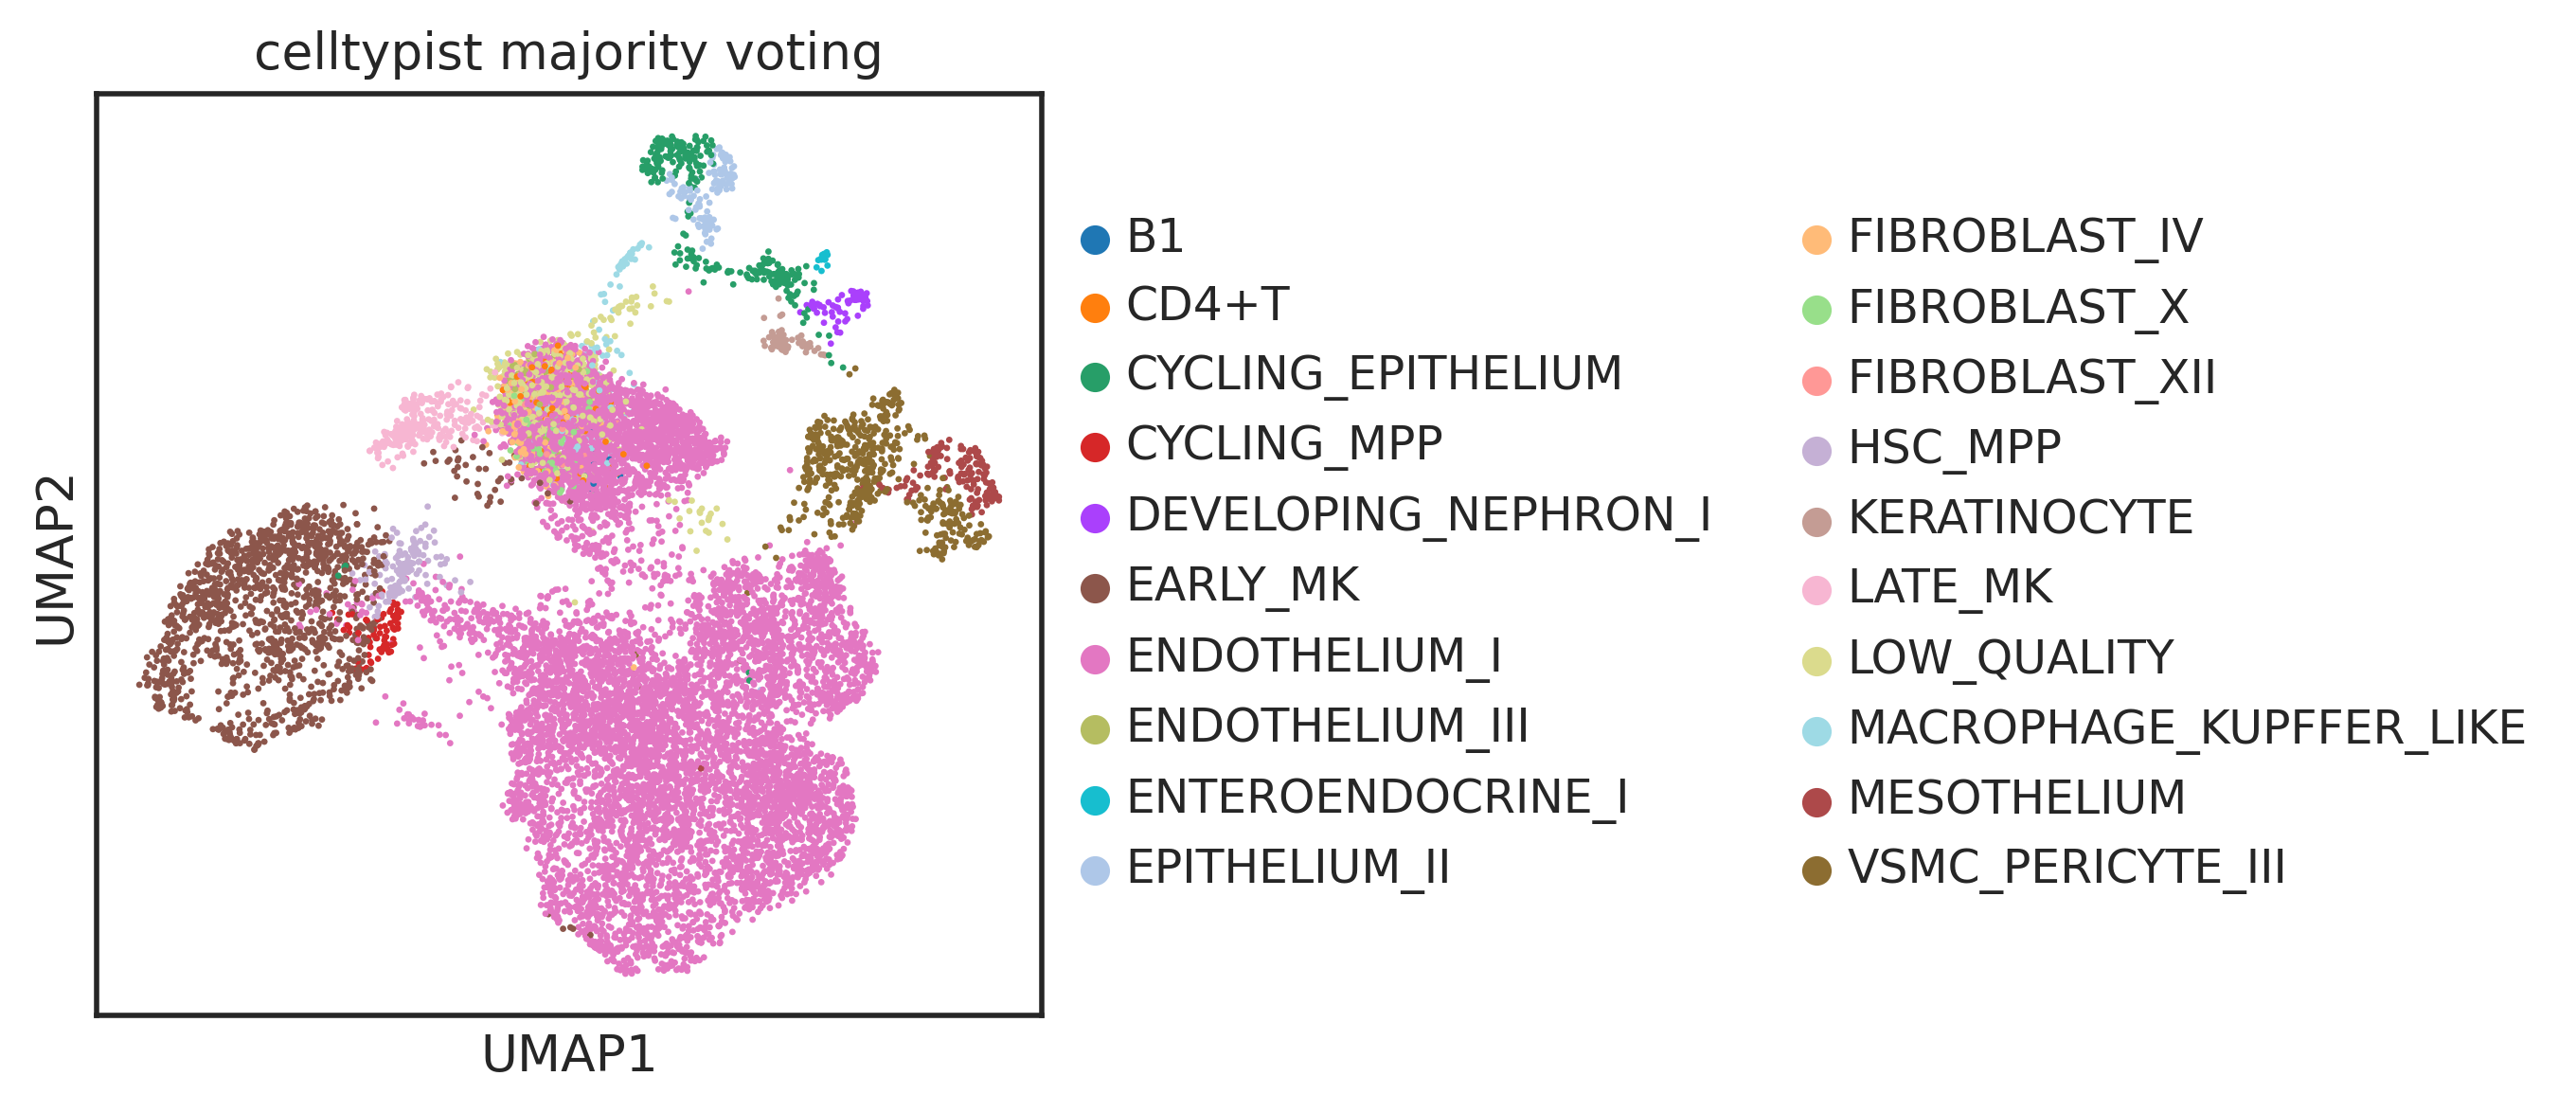

In [49]:
sc.pl.umap(adata, color=['majority_voting'], title = ['celltypist majority voting'], save = 'CONSTITUTIVE_SPI1_celltypist.pdf')

# Use celltypist majority voting results

In [22]:
# group cell types into broad groups 
adata.obs['celltypist_broad'] = 'OTHER'
adata.obs.loc[adata.obs['majority_voting'].isin(['CYCILNG_MPP','HSC_MPP']),'celltypist_broad'] = 'HSC_MPP'
adata.obs.loc[adata.obs['majority_voting'].isin(['B1','CD4+T','EARLY_MK','LATE_MK']),'celltypist_broad'] = 'HAEMATOPOIETIC'
adata.obs.loc[adata.obs['majority_voting'].isin(['ENDOTHELIUM_I','ENDOTHELIUM_III']),'celltypist_broad'] = 'ENDOTHELIUM'

In [32]:
# remove cells without any TF calling and EGFP (only 2 cells)
df = adata.obs.loc[adata.obs['TF_calling'].isin(['EXOG_GFI1', 'EXOG_GFI1B', 'EXOG_HLF', 'EXOG_NFE2', 'EXOG_SPI1']),['TF_calling', 'celltypist_broad']]
# remove EXOG_
df['TF_calling'] = [gene.split('_')[1] for gene in df['TF_calling']]

In [34]:
# count cells
df_counts = (
    df
    .groupby(['TF_calling', 'celltypist_broad'])
    .size()
    .reset_index(name='count')
)

# compute percentages within each antibody
df_counts['percent'] = (
    df_counts
    .groupby('TF_calling')['count']
    .transform(lambda x: 100 * x / x.sum())
)

/tmp/ipykernel_1454/2164643818.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[80.11527378 62.28956229 66.49642492 75.08389262 20.52401747]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  bottom[subset["TF_calling"]] += subset["percent"].values


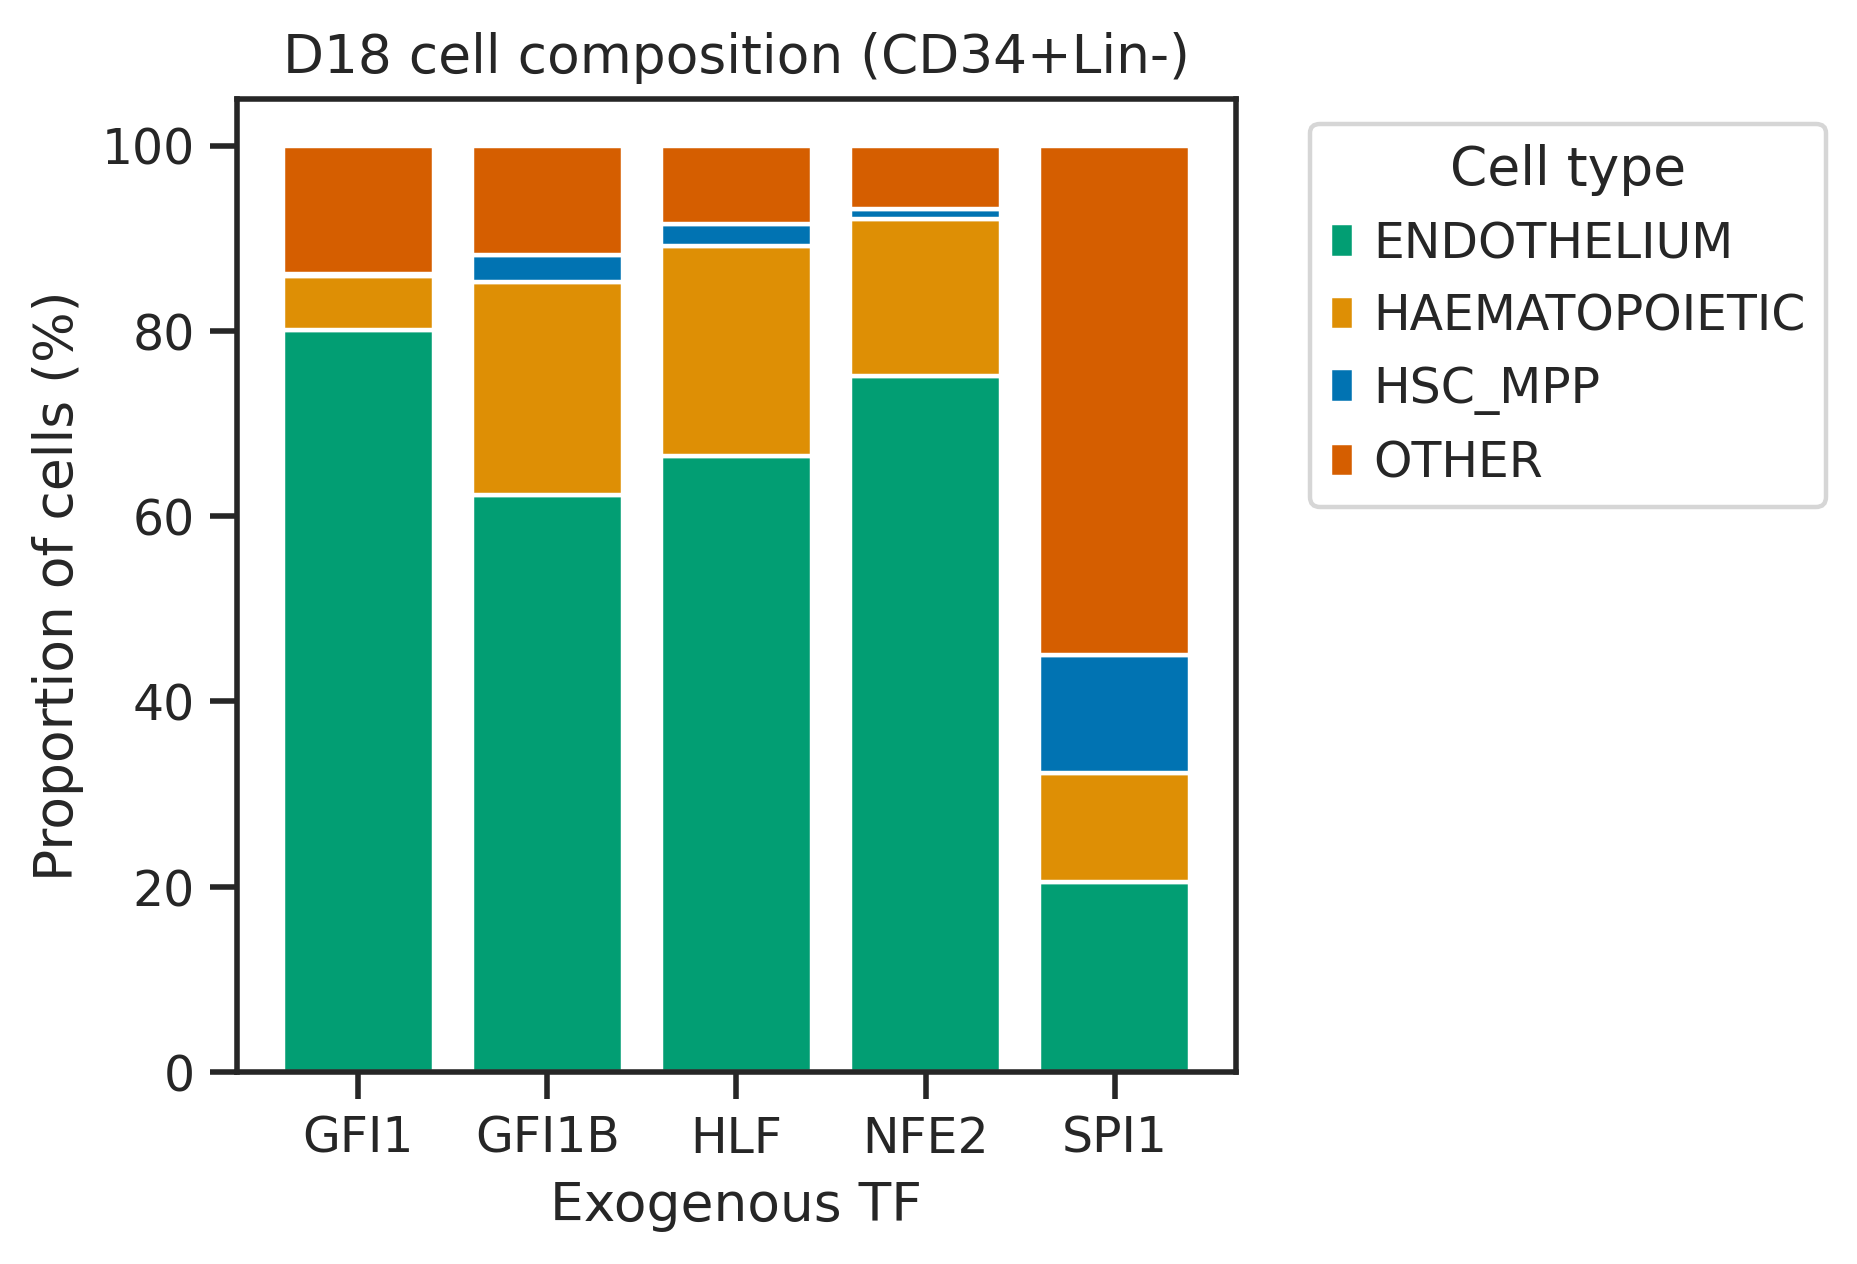

In [52]:
sb.set_theme(style = 'ticks')
plt.figure(figsize=(4, 4))

bottom = pd.Series(0, index=df_counts["TF_calling"].unique())

for cell_type in df_counts["celltypist_broad"].unique():
    subset = df_counts[df_counts["celltypist_broad"] == cell_type]
    plt.bar(
        subset["TF_calling"],
        subset["percent"],
        bottom=bottom[subset["TF_calling"]].values,
        label=cell_type,
        color=palette_dict[cell_type]
    )
    bottom[subset["TF_calling"]] += subset["percent"].values

plt.ylabel("Proportion of cells (%)")
plt.xlabel("Exogenous TF")
plt.title('D18 cell composition (CD34+Lin-)')
plt.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.savefig(fig_path+"D18_celltypes_CONSTITUTIVE_SPI1.pdf", bbox_inches='tight')

In [45]:
hsc = adata[adata.obs['majority_voting'].isin(['CYCLING_MPP','HSC_MPP'])]
hsc.write_h5ad('write/SPI1_CONSTITUTIVE_selected_HSC.h5ad')

/home/jovyan/my-conda-envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1180: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [46]:
Counter(hsc.obs['TF_calling'])

Counter({nan: 65,
         'EXOG_GFI1B': 50,
         'EXOG_SPI1': 46,
         'EXOG_HLF': 34,
         'EXOG_NFE2': 13,
         'EXOG_GFI1': 1})